<center><h1>Zhu_Lingfei_HW4</h1></center>
<br>
<br>

Name: Zhu Lingfei
<br>
Github Username: youth0505
<br>
USC ID: 8599420339

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

SENSOR_COLUMNS = [
    "avg_rss12", "var_rss12",
    "avg_rss13", "var_rss13",
    "avg_rss23", "var_rss23"
]
STATS = ["min", "max", "mean", "median", "std", "q1", "q3"]

def read_file(path):
    return pd.read_csv(
        path,
        comment="#",
        header=None,
        names=["time"] + SENSOR_COLUMNS,
        sep=r"\s*,\s*|\s+",
        engine="python",
        usecols=range(7)
    )[SENSOR_COLUMNS]

def get_features(data):
    result = {}

    for col in SENSOR_COLUMNS:
        x = data[col]
        result.update({
            f"min_{col}": x.min(),
            f"max_{col}": x.max(),
            f"mean_{col}": x.mean(),
            f"median_{col}": x.median(),
            f"std_{col}": x.std(),
            f"q1_{col}": x.quantile(0.25),
            f"q3_{col}": x.quantile(0.75)
        })

    return result

Get the AReM Data Set

In [3]:
DATA_DIR = Path("../HW4/Homework 3, 4 Data/AReM")

if not DATA_DIR.exists():
    DATA_DIR = Path("Homework 3, 4 Data/AReM")

files = sorted(DATA_DIR.glob("*/*.csv"))
data = {path: read_file(path) for path in files}

print(f"Loaded {len(files)} files")
print("Rows per file:", pd.Series(
    [len(frame) for frame in data.values()]
).value_counts().to_dict())

Loaded 88 files
Rows per file: {480: 87, 479: 1}


### (b) Splitting Data

In [4]:
test_files = []
train_files = []

for path in files:
    number = int(path.stem.replace("dataset", ""))

    is_test = (
        path.parent.name.startswith("bending")
        and number in [1, 2]
    )

    is_test |= (
        not path.parent.name.startswith("bending")
        and number in [1, 2, 3]
    )

    if is_test:
        test_files.append(path)
    else:
        train_files.append(path)

print(f"Training: {len(train_files)}")
print(f"Test: {len(test_files)}")

Training: 69
Test: 19


### (c) Feature Extraction

In [5]:
def make_features(paths):
    rows = []

    for path in paths:
        row = get_features(data[path])

        if path.parent.name.startswith("bending"):
            row["activity"] = "bending"
        else:
            row["activity"] = path.parent.name

        row["instance"] = f"{path.parent.name}/{path.stem}"
        rows.append(row)

    frame = pd.DataFrame(rows).set_index("instance")

    columns = [
        f"{stat}_{col}"
        for col in SENSOR_COLUMNS
        for stat in STATS
    ]

    return frame[columns + ["activity"]]


features = make_features(files)
train_features = make_features(train_files)
test_features = make_features(test_files)

feature_columns = features.columns[:-1]

print("All features:", features.shape)
print("Train features:", train_features.shape)
print("Test features:", test_features.shape)

display(features.head())

rng = np.random.default_rng(552)

results = {}

for name in feature_columns:
    x = features[name].to_numpy()

    boot_std = [
        rng.choice(x, len(x), replace=True).std(ddof=1)
        for _ in range(10000)
    ]

    results[name] = [
        x.std(ddof=1),
        *np.quantile(boot_std, [0.05, 0.95])
    ]

std_ci = pd.DataFrame.from_dict(
    results,
    orient="index",
    columns=["std", "90% CI lower", "90% CI upper"]
)

display(std_ci.round(4))

All features: (88, 43)
Train features: (69, 43)
Test features: (19, 43)


,min_avg_rss12,max_avg_rss12,mean_avg_rss12,median_avg_rss12,std_avg_rss12,q1_avg_rss12,q3_avg_rss12,min_var_rss12,max_var_rss12,mean_var_rss12,...,q1_avg_rss23,q3_avg_rss23,min_var_rss23,max_var_rss23,mean_var_rss23,median_var_rss23,std_var_rss23,q1_var_rss23,q3_var_rss23,activity
instance,,,,,,,,,,,,,,,,,,,,,
bending1/dataset1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,0.358604,...,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30,bending
bending1/dataset2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,0.372437,...,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30,bending
bending1/dataset3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94,bending
bending1/dataset4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00,bending
bending1/dataset5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50,bending


,std,90% CI lower,90% CI upper
min_avg_rss12,9.5700,8.2569,10.7417
max_avg_rss12,4.3944,3.3280,5.3082
mean_avg_rss12,5.3357,4.7128,5.8836
median_avg_rss12,5.4401,4.8092,5.9993
std_avg_rss12,1.7722,1.5726,1.9494
q1_avg_rss12,6.1536,5.5706,6.6526
q3_avg_rss12,5.1389,4.3307,5.8409
min_var_rss12,0.0000,0.0000,0.0000
max_var_rss12,5.0627,4.6327,5.4113
mean_var_rss12,1.5742,1.3908,1.7068


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

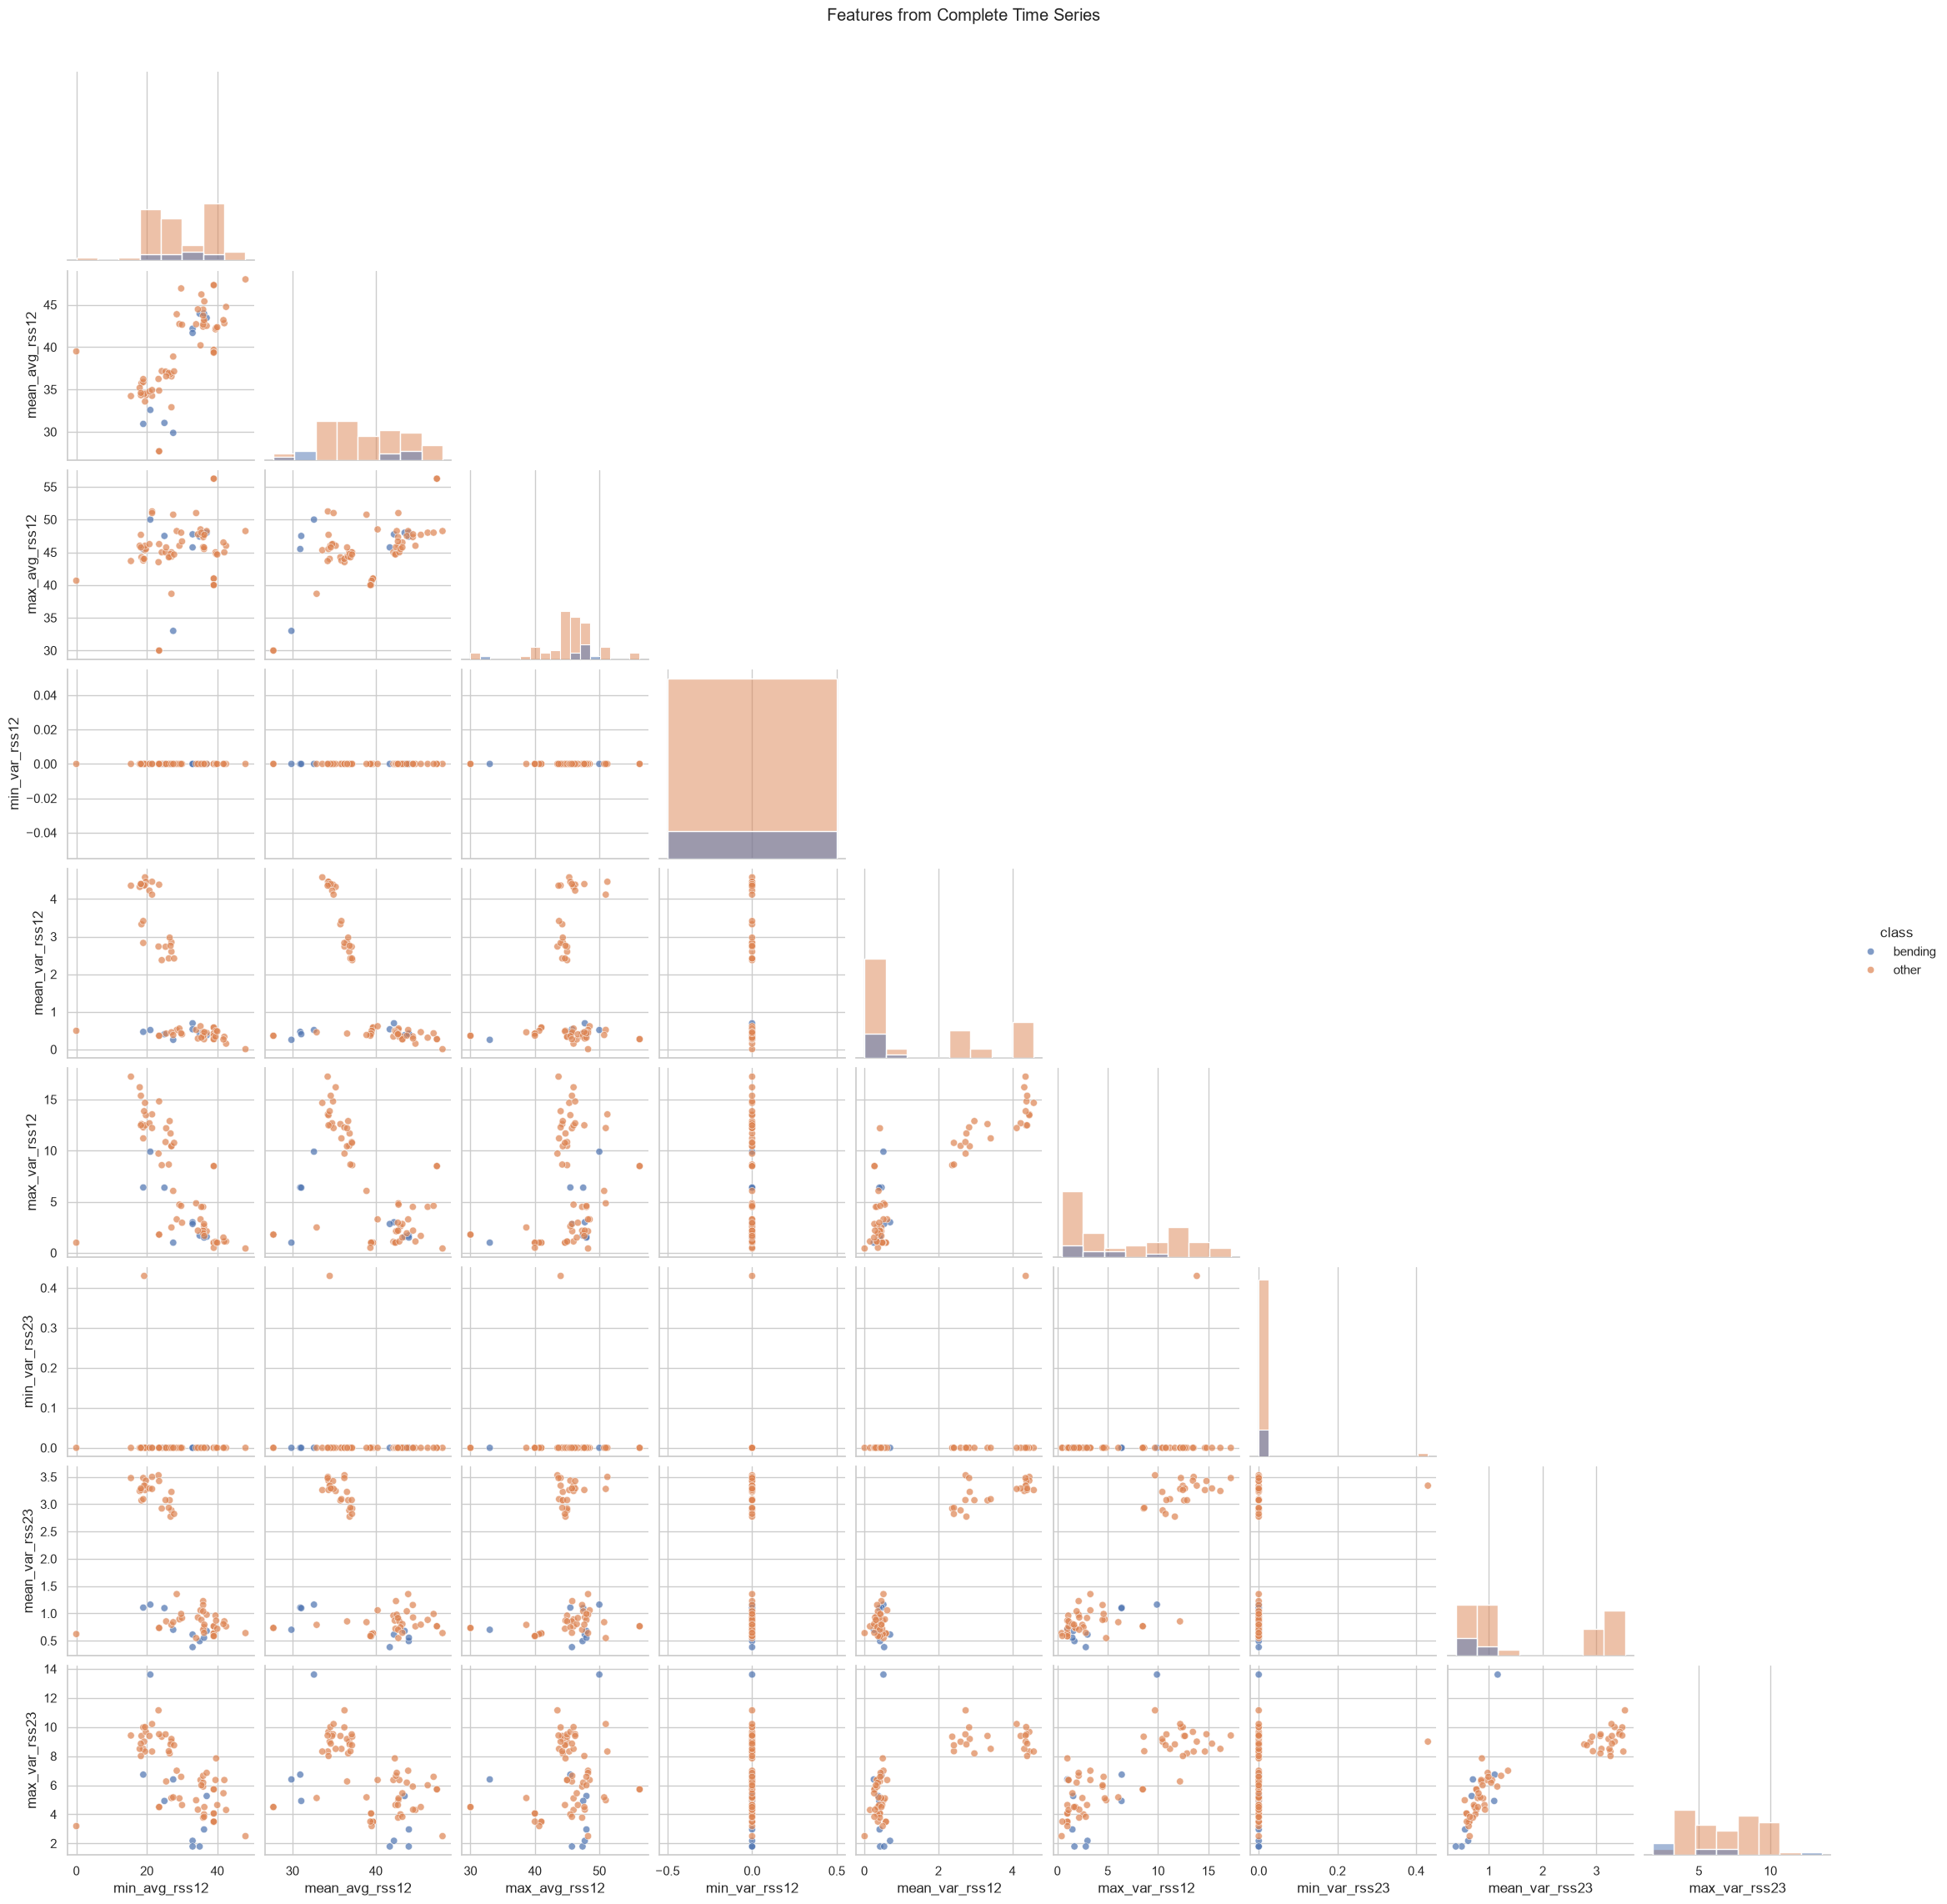

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

PLOT_SENSORS = [
    "avg_rss12",
    "var_rss12",
    "var_rss23"
]

PLOT_FEATURES = [
    f"{stat}_{sensor}"
    for sensor in PLOT_SENSORS
    for stat in ["min", "mean", "max"]
]

plot_data = train_features[PLOT_FEATURES].copy()

plot_data["class"] = np.where(
    train_features["activity"] == "bending",
    "bending",
    "other"
)

sns.pairplot(
    plot_data,
    vars=PLOT_FEATURES,
    hue="class",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.7}
)

plt.suptitle(
    "Features from Complete Time Series",
    y=1.02
)

plt.show()

#### ii. Splitted Plots

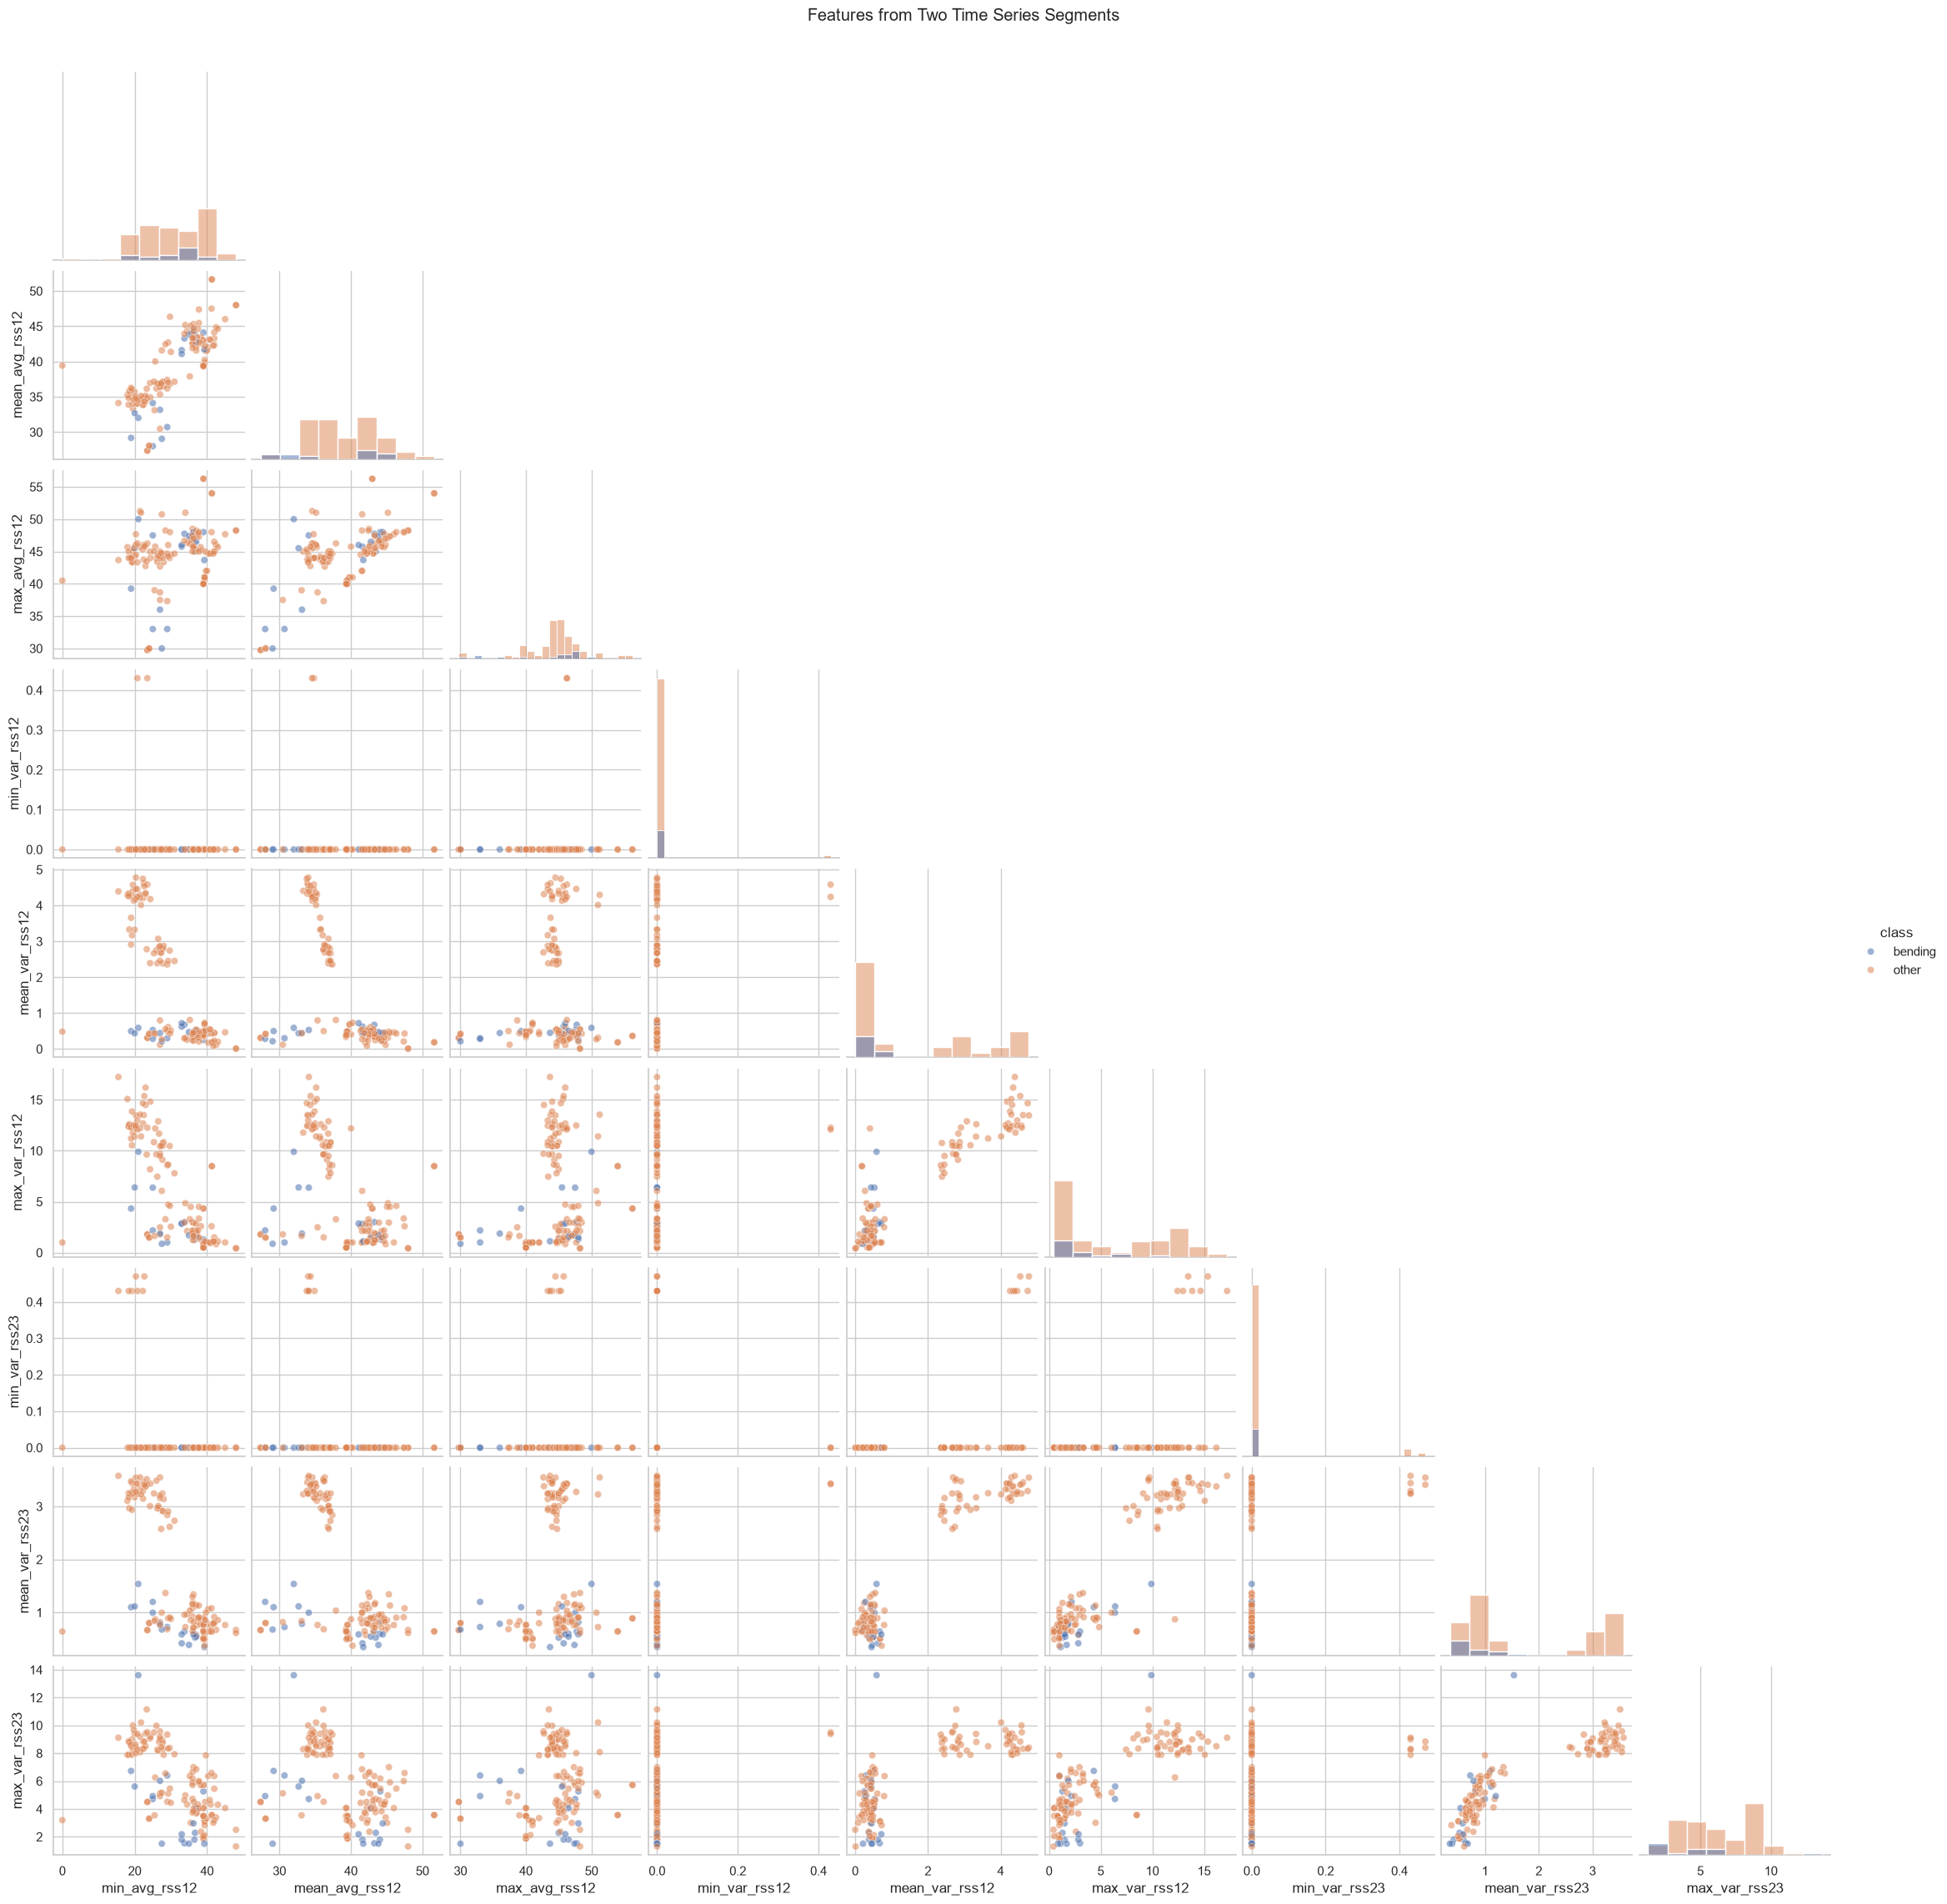

In [7]:
def make_segment_features(paths, l):
    rows = []

    for path in paths:
        row = {}

        parts = np.array_split(
            data[path].to_numpy(),
            l
        )

        for i, part in enumerate(parts, start=1):
            part_df = pd.DataFrame(
                part,
                columns=SENSOR_COLUMNS
            )

            part_features = get_features(part_df)

            for name, value in part_features.items():
                row[f"s{i}_{name}"] = value

        if path.parent.name.startswith("bending"):
            row["activity"] = "bending"
        else:
            row["activity"] = path.parent.name

        row["instance"] = f"{path.parent.name}/{path.stem}"
        rows.append(row)

    return pd.DataFrame(rows).set_index("instance")


two_segment_features = make_segment_features(
    train_files,
    2
)

plot_frames = []

for segment in [1, 2]:
    segment_data = two_segment_features[
        [f"s{segment}_{feature}" for feature in PLOT_FEATURES]
    ].copy()

    segment_data.columns = PLOT_FEATURES

    segment_data["class"] = np.where(
        two_segment_features["activity"] == "bending",
        "bending",
        "other"
    )

    segment_data["segment"] = f"segment {segment}"
    plot_frames.append(segment_data)

split_plot_data = pd.concat(plot_frames)

sns.pairplot(
    split_plot_data,
    vars=PLOT_FEATURES,
    hue="class",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.55}
)

plt.suptitle(
    "Features from Two Time Series Segments",
    y=1.02
)

plt.show()

The features extracted from the two time-series segments are generally similar to those from the complete time series. After splitting, the samples are more dispersed for some features, but bending and other activities still show some separation.

#### iii. Time Series Segments

In [9]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=552
)

def rfe_pipeline(p):
    base_model = LogisticRegression(
        C=1e6,
        solver="liblinear",
        max_iter=5000,
        random_state=552
    )

    return Pipeline([
        ("scale", StandardScaler()),
        (
            "rfe",
            RFE(
                estimator=base_model,
                n_features_to_select=p,
                step=0.2
            )
        ),
        ("model", base_model)
    ])


y_train = (
    train_features["activity"] == "bending"
).astype(int).to_numpy()

results = []

for l in range(1, 21):
    X_l = make_segment_features(
        train_files,
        l
    ).drop(columns="activity")

    p_values = [
        p for p in [3, 6, 12, 24, 48]
        if p <= X_l.shape[1]
    ]

    search = GridSearchCV(
        estimator=rfe_pipeline(p_values[0]),
        param_grid={
            "rfe__n_features_to_select": p_values
        },
        scoring="accuracy",
        cv=cv,
        n_jobs=-1
    )

    search.fit(X_l, y_train)

    results.append({
        "l": l,
        "p": search.best_params_[
            "rfe__n_features_to_select"
        ],
        "CV accuracy": search.best_score_
    })

binary_cv_results = pd.DataFrame(results)

binary_cv_results = binary_cv_results.sort_values(
    "CV accuracy",
    ascending=False
).reset_index(drop=True)

display(binary_cv_results)

best_row = binary_cv_results.iloc[0]

best_l = int(best_row["l"])
best_p = int(best_row["p"])

X_binary_train = make_segment_features(
    train_files,
    best_l
).drop(columns="activity")

X_binary_test = make_segment_features(
    test_files,
    best_l
).drop(columns="activity")

binary_model = rfe_pipeline(best_p)

binary_model.fit(
    X_binary_train,
    y_train
)

selected_mask = binary_model.named_steps[
    "rfe"
].support_

selected_features = X_binary_train.columns[
    selected_mask
]

print(f"Best l: {best_l}")
print(f"Best p: {best_p}")
print(f"Best CV accuracy: {best_row['CV accuracy']:.3f}")

print("\nSelected features:")
print(selected_features.tolist())

####################### p
scaled_train = binary_model.named_steps[
    "scale"
].transform(X_binary_train)

X_selected = scaled_train[:, selected_mask]

glm_model = sm.GLM(
    y_train,
    sm.add_constant(X_selected),
    family=sm.families.Binomial()
).fit()

coefficient_table = pd.DataFrame({
    "coefficient": glm_model.params,
    "p-value": glm_model.pvalues
})

coefficient_table.index = [
    "intercept",
    *selected_features
]

display(coefficient_table.round(5))

,l,p,CV accuracy
0,1,3,0.957143
1,3,6,0.957143
2,2,6,0.942857
3,4,48,0.942857
4,12,12,0.942857
5,19,12,0.942857
6,6,12,0.941758
7,10,12,0.928571
8,20,48,0.928571
9,11,48,0.928571


Best l: 1
Best p: 3
Best CV accuracy: 0.957

Selected features:
['s1_q1_var_rss13', 's1_min_avg_rss23', 's1_max_avg_rss23']


E:\ANACONDA\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
E:\ANACONDA\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
E:\ANACONDA\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)


,coefficient,p-value
intercept,-118.10445,0.99887
s1_q1_var_rss13,-48.40985,0.99941
s1_min_avg_rss23,83.64681,0.99899
s1_max_avg_rss23,61.96195,0.99890


The classes appear to be well separated. Statsmodels produced perfect separation warnings when fitting the unpenalized logistic regression model. This means that some selected features can almost perfectly distinguish bending from other activities, so the maximum likelihood estimates and their p-values may be unstable.

#### iv. Confusion Matrix

Training accuracy: 1.000
Training AUC: 1.000


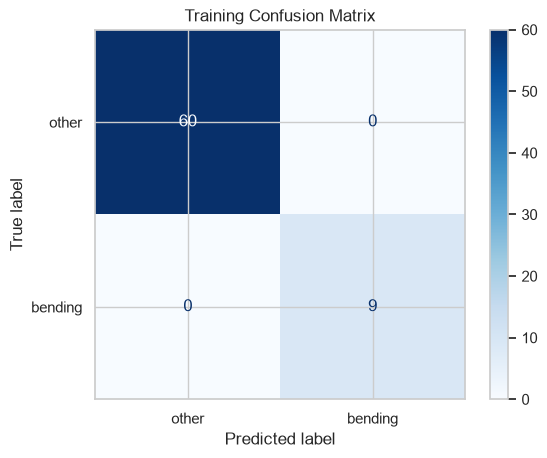

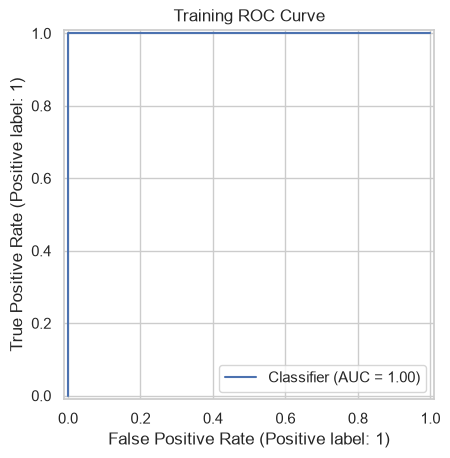

,coefficient,p-value
intercept,-118.10445,0.99887
s1_q1_var_rss13,-48.40985,0.99941
s1_min_avg_rss23,83.64681,0.99899
s1_max_avg_rss23,61.96195,0.99890


In [10]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)

train_probability = binary_model.predict_proba(
    X_binary_train
)[:, 1]

train_prediction = (
    train_probability >= 0.5
).astype(int)

train_accuracy = accuracy_score(
    y_train,
    train_prediction
)

train_auc = roc_auc_score(
    y_train,
    train_probability
)

print(f"Training accuracy: {train_accuracy:.3f}")
print(f"Training AUC: {train_auc:.3f}")

ConfusionMatrixDisplay(
    confusion_matrix(y_train, train_prediction),
    display_labels=["other", "bending"]
).plot(cmap="Blues")

plt.title("Training Confusion Matrix")
plt.show()

RocCurveDisplay.from_predictions(
    y_train,
    train_probability
)

plt.title("Training ROC Curve")
plt.show()

display(coefficient_table.round(5))

#### v. Test Classifier

Cross-validation accuracy: 0.957
Test accuracy: 0.947
Test AUC: 1.000


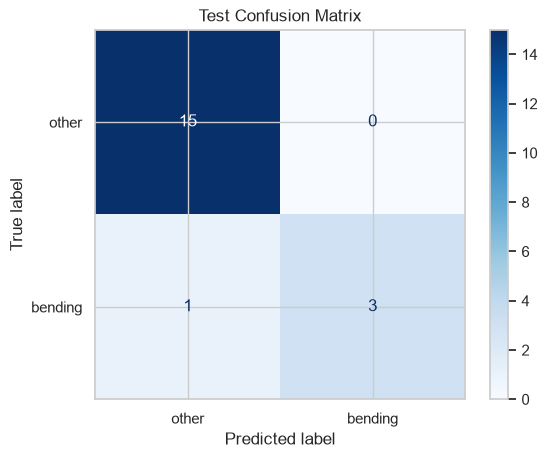

In [11]:
y_test = (
    test_features["activity"] == "bending"
).astype(int).to_numpy()

test_probability = binary_model.predict_proba(
    X_binary_test
)[:, 1]

test_prediction = (
    test_probability >= 0.5
).astype(int)

test_accuracy = accuracy_score(
    y_test,
    test_prediction
)

test_auc = roc_auc_score(
    y_test,
    test_probability
)

print(f"Cross-validation accuracy: {best_row['CV accuracy']:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Test AUC: {test_auc:.3f}")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, test_prediction),
    display_labels=["other", "bending"]
).plot(cmap="Blues")

plt.title("Test Confusion Matrix")
plt.show()

#### vi. Separation

The classes appear to be well separated. Perfect separation warnings occurred when fitting the unpenalized logistic regression model, which suggests that some selected features can almost perfectly distinguish bending from other activities. Therefore, the estimated coefficients and p-values may be unstable.

#### vii. Imbalance

Original bending proportion: 0.130
Case-control bending proportion: 0.500
Adjusted AUC: 1.000


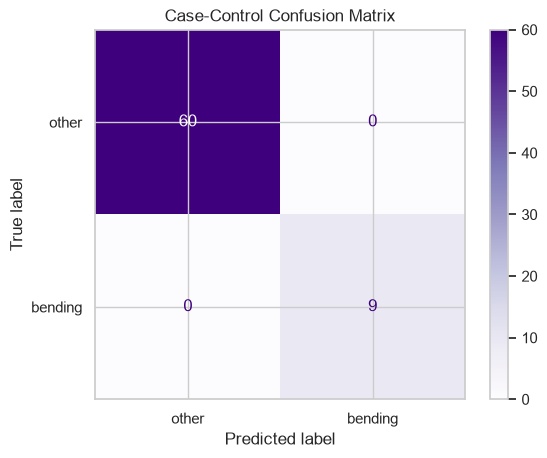

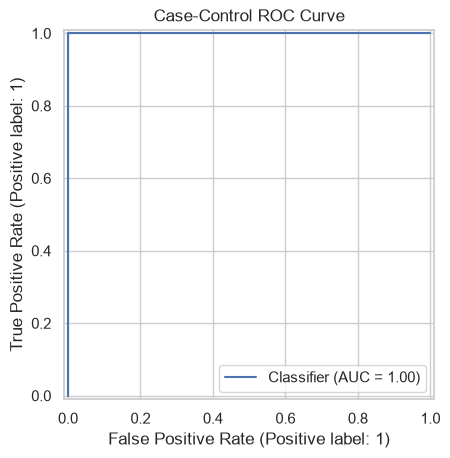

In [12]:
rng = np.random.default_rng(552)

positive_index = np.flatnonzero(y_train == 1)
negative_index = np.flatnonzero(y_train == 0)

sampled_negative_index = rng.choice(
    negative_index,
    size=len(positive_index),
    replace=False
)

case_control_index = np.concatenate([
    positive_index,
    sampled_negative_index
])

X_case_control = X_binary_train.iloc[
    case_control_index
]

y_case_control = y_train[
    case_control_index
]

case_control_model = rfe_pipeline(best_p)

case_control_model.fit(
    X_case_control,
    y_case_control
)

case_control_probability = (
    case_control_model.predict_proba(
        X_binary_train
    )[:, 1]
)

population_prior = y_train.mean()
sample_prior = y_case_control.mean()

case_control_probability = np.clip(
    case_control_probability,
    1e-10,
    1 - 1e-10
)

sample_log_odds = np.log(
    case_control_probability /
    (1 - case_control_probability)
)

adjusted_log_odds = (
    sample_log_odds
    - np.log(sample_prior / (1 - sample_prior))
    + np.log(
        population_prior /
        (1 - population_prior)
    )
)

adjusted_probability = 1 / (
    1 + np.exp(-adjusted_log_odds)
)

adjusted_prediction = (
    adjusted_probability >= 0.5
).astype(int)

adjusted_auc = roc_auc_score(
    y_train,
    adjusted_probability
)

print(f"Original bending proportion: {population_prior:.3f}")
print(f"Case-control bending proportion: {sample_prior:.3f}")
print(f"Adjusted AUC: {adjusted_auc:.3f}")

ConfusionMatrixDisplay(
    confusion_matrix(y_train, adjusted_prediction),
    display_labels=["other", "bending"]
).plot(cmap="Purples")

plt.title("Case-Control Confusion Matrix")
plt.show()

RocCurveDisplay.from_predictions(
    y_train,
    adjusted_probability
)

plt.title("Case-Control ROC Curve")
plt.show()

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

l1_results = []

for l in range(1, 21):
    X_l = make_segment_features(
        train_files,
        l
    ).drop(columns="activity")

    l1_pipeline = Pipeline([
        ("scale", StandardScaler()),
        (
            "model",
            LogisticRegression(
                solver="liblinear",
                l1_ratio=1,
                max_iter=5000,
                random_state=552
            )
        )
    ])

    search = GridSearchCV(
        estimator=l1_pipeline,
        param_grid={
            "model__C": np.logspace(-3, 3, 7)
        },
        scoring="accuracy",
        cv=cv,
        n_jobs=-1
    )

    search.fit(X_l, y_train)

    l1_results.append({
        "l": l,
        "C": search.best_params_["model__C"],
        "CV accuracy": search.best_score_
    })

    print(
        f"l = {l}, "
        f"best C = {search.best_params_['model__C']:.4g}, "
        f"accuracy = {search.best_score_:.3f}"
    )

l1_cv_results = pd.DataFrame(l1_results)

l1_cv_results = l1_cv_results.sort_values(
    "CV accuracy",
    ascending=False
).reset_index(drop=True)

display(l1_cv_results)

best_l1_row = l1_cv_results.iloc[0]

best_l1 = int(best_l1_row["l"])
best_C = best_l1_row["C"]

X_l1_train = make_segment_features(
    train_files,
    best_l1
).drop(columns="activity")

X_l1_test = make_segment_features(
    test_files,
    best_l1
).drop(columns="activity")

l1_model = Pipeline([
    ("scale", StandardScaler()),
    (
        "model",
        LogisticRegression(
            solver="liblinear",
            l1_ratio=1,
            C=best_C,
            max_iter=5000,
            random_state=552
        )
    )
])

l1_model.fit(
    X_l1_train,
    y_train
)

l1_train_accuracy = l1_model.score(
    X_l1_train,
    y_train
)

l1_test_accuracy = l1_model.score(
    X_l1_test,
    y_test
)

l1_probability = l1_model.predict_proba(
    X_l1_test
)[:, 1]

l1_test_auc = roc_auc_score(
    y_test,
    l1_probability
)

nonzero_coefficients = np.count_nonzero(
    l1_model.named_steps["model"].coef_
)

print("\nFinal L1 model")
print(f"Best l: {best_l1}")
print(f"Best C: {best_C:.4g}")
print(f"Best CV accuracy: {best_l1_row['CV accuracy']:.3f}")
print(f"Training accuracy: {l1_train_accuracy:.3f}")
print(f"Test accuracy: {l1_test_accuracy:.3f}")
print(f"Test AUC: {l1_test_auc:.3f}")
print(
    f"Non-zero coefficients: "
    f"{nonzero_coefficients} / {X_l1_train.shape[1]}"
)

l = 1, best C = 1, accuracy = 0.986
l = 2, best C = 1, accuracy = 0.943
l = 3, best C = 1, accuracy = 0.957
l = 4, best C = 1, accuracy = 0.957
l = 5, best C = 100, accuracy = 0.914
l = 6, best C = 1000, accuracy = 0.943
l = 7, best C = 1, accuracy = 0.943
l = 8, best C = 1, accuracy = 0.927
l = 9, best C = 1, accuracy = 0.913
l = 10, best C = 100, accuracy = 0.914
l = 11, best C = 1, accuracy = 0.957
l = 12, best C = 1, accuracy = 0.971
l = 13, best C = 1, accuracy = 0.971
l = 14, best C = 1, accuracy = 0.914
l = 15, best C = 1, accuracy = 0.900
l = 16, best C = 1, accuracy = 0.914
l = 17, best C = 10, accuracy = 0.943
l = 18, best C = 1, accuracy = 0.957
l = 19, best C = 1, accuracy = 0.957
l = 20, best C = 1, accuracy = 0.971


,l,C,CV accuracy
0,1,1.0,0.985714
1,20,1.0,0.971429
2,13,1.0,0.971429
3,12,1.0,0.971429
4,19,1.0,0.957143
5,4,1.0,0.957143
6,3,1.0,0.957143
7,11,1.0,0.957143
8,18,1.0,0.957143
9,2,1.0,0.942857



Final L1 model
Best l: 1
Best C: 1
Best CV accuracy: 0.986
Training accuracy: 1.000
Test accuracy: 1.000
Test AUC: 1.000
Non-zero coefficients: 7 / 42


#### ii. Comparison

The L1-penalized logistic regression achieved a test accuracy of 1.000, while the RFE logistic regression achieved a test accuracy of 0.947. Therefore, the L1-penalized logistic regression performed better on the test set. The L1 model was also easier to implement because feature selection and model fitting were performed at the same time.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

l = 1, best C = 1, accuracy = 0.914
l = 2, best C = 100, accuracy = 0.869
l = 3, best C = 100, accuracy = 0.884
l = 4, best C = 100, accuracy = 0.870
l = 5, best C = 10, accuracy = 0.885
l = 6, best C = 10, accuracy = 0.856
l = 7, best C = 10, accuracy = 0.842
l = 8, best C = 100, accuracy = 0.841
l = 9, best C = 100, accuracy = 0.870
l = 10, best C = 10, accuracy = 0.813
l = 11, best C = 10, accuracy = 0.812
l = 12, best C = 10, accuracy = 0.827
l = 13, best C = 100, accuracy = 0.812
l = 14, best C = 1, accuracy = 0.826
l = 15, best C = 100, accuracy = 0.811
l = 16, best C = 100, accuracy = 0.812
l = 17, best C = 100, accuracy = 0.841
l = 18, best C = 1, accuracy = 0.856
l = 19, best C = 100, accuracy = 0.826
l = 20, best C = 100, accuracy = 0.840


,l,C,CV accuracy
0,1,1.0,0.914286
1,5,10.0,0.884615
2,3,100.0,0.883516
3,4,100.0,0.870330
4,9,100.0,0.870330
5,2,100.0,0.869231
6,6,10.0,0.856044
7,18,1.0,0.856044
8,7,10.0,0.841758
9,8,100.0,0.840659



Best l: 1
Best C: 1
Best CV accuracy: 0.914
Test accuracy: 0.895
Test error: 0.105


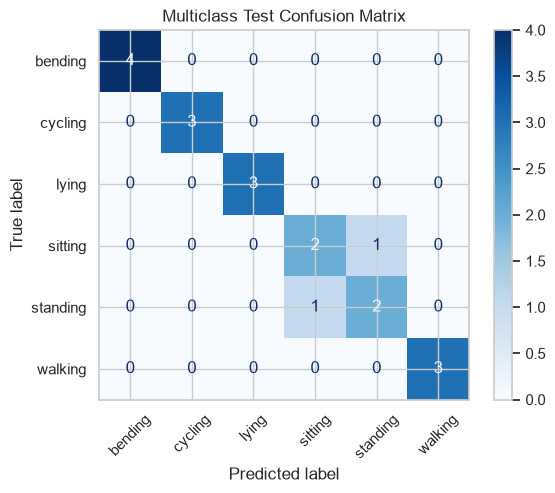

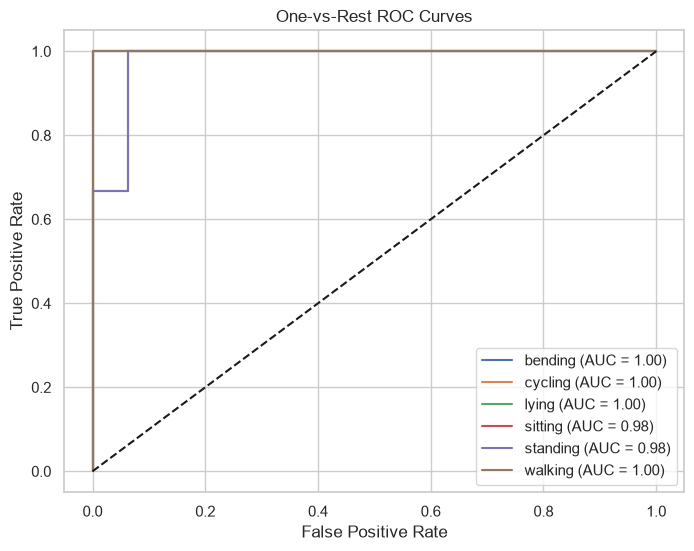

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

y_multi_train = train_features["activity"].to_numpy()
y_multi_test = test_features["activity"].to_numpy()

multi_results = []

for l in range(1, 21):
    X_l = make_segment_features(
        train_files,
        l
    ).drop(columns="activity")

    multi_pipeline = Pipeline([
        ("scale", StandardScaler()),
        (
            "model",
            LogisticRegression(
                solver="saga",
                l1_ratio=1,
                max_iter=3000,
                tol=1e-3,
                random_state=552
            )
        )
    ])

    search = GridSearchCV(
        estimator=multi_pipeline,
        param_grid={
            "model__C": np.logspace(-3, 2, 6)
        },
        scoring="accuracy",
        cv=cv,
        n_jobs=-1
    )

    search.fit(X_l, y_multi_train)

    multi_results.append({
        "l": l,
        "C": search.best_params_["model__C"],
        "CV accuracy": search.best_score_
    })

    print(
        f"l = {l}, "
        f"best C = {search.best_params_['model__C']:.4g}, "
        f"accuracy = {search.best_score_:.3f}"
    )

multi_cv_results = pd.DataFrame(multi_results)

multi_cv_results = multi_cv_results.sort_values(
    "CV accuracy",
    ascending=False
).reset_index(drop=True)

display(multi_cv_results)

best_multi_row = multi_cv_results.iloc[0]

best_multi_l = int(best_multi_row["l"])
best_multi_C = best_multi_row["C"]

X_multi_train = make_segment_features(
    train_files,
    best_multi_l
).drop(columns="activity")

X_multi_test = make_segment_features(
    test_files,
    best_multi_l
).drop(columns="activity")

multi_model = Pipeline([
    ("scale", StandardScaler()),
    (
        "model",
        LogisticRegression(
            solver="saga",
            l1_ratio=1,
            C=best_multi_C,
            max_iter=3000,
            tol=1e-3,
            random_state=552
        )
    )
])

multi_model.fit(X_multi_train, y_multi_train)

multi_prediction = multi_model.predict(X_multi_test)

multi_probability = multi_model.predict_proba(
    X_multi_test
)

class_labels = multi_model.classes_

multi_test_accuracy = accuracy_score(
    y_multi_test,
    multi_prediction
)

multi_test_error = 1 - multi_test_accuracy

print(f"\nBest l: {best_multi_l}")
print(f"Best C: {best_multi_C:.4g}")
print(f"Best CV accuracy: {best_multi_row['CV accuracy']:.3f}")
print(f"Test accuracy: {multi_test_accuracy:.3f}")
print(f"Test error: {multi_test_error:.3f}")

ConfusionMatrixDisplay(
    confusion_matrix(
        y_multi_test,
        multi_prediction,
        labels=class_labels
    ),
    display_labels=class_labels
).plot(
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Multiclass Test Confusion Matrix")
plt.show()

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(class_labels):
    y_true_binary = (
        y_multi_test == class_name
    ).astype(int)

    fpr, tpr, _ = roc_curve(
        y_true_binary,
        multi_probability[:, i]
    )

    class_auc = roc_auc_score(
        y_true_binary,
        multi_probability[:, i]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {class_auc:.2f})"
    )

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC Curves")
plt.legend()
plt.show()

The L1-penalized multinomial logistic regression selected \(l=1\) and \(C=1\). It achieved a cross-validation accuracy of 0.914 and a test error of 0.105.

#### ii. Naive Bayes

GaussianNB


,l,CV accuracy
0,1,0.854945
1,2,0.812088
2,5,0.709890
3,3,0.708791
4,8,0.708791


MultinomialNB


,l,CV accuracy
0,5,0.812088
1,8,0.795604
2,19,0.781319
3,6,0.768132
4,13,0.767033


GaussianNB best l: 1
GaussianNB test accuracy: 0.895
GaussianNB test error: 0.105

MultinomialNB best l: 5
MultinomialNB test accuracy: 0.842
MultinomialNB test error: 0.158


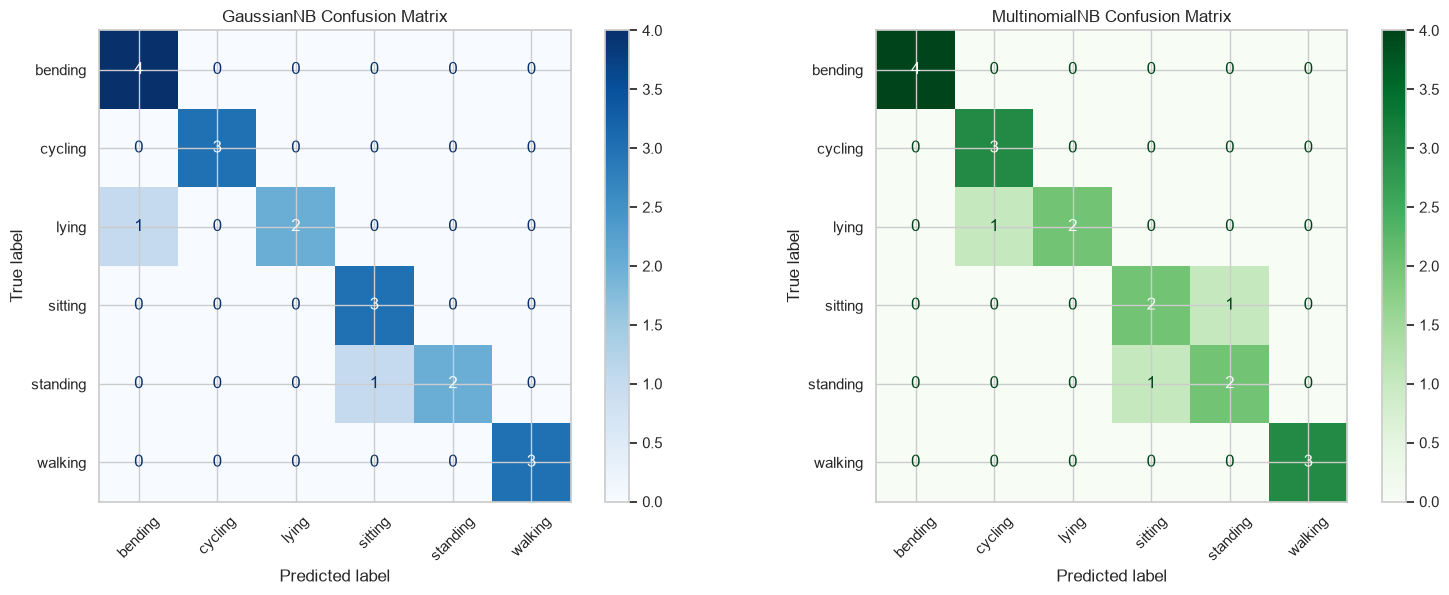

In [16]:
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler
)

def find_best_nb(model_pipeline):
    results = []

    for l in range(1, 21):
        X_l = make_segment_features(
            train_files,
            l
        ).drop(columns="activity")

        cv_accuracy = cross_val_score(
            model_pipeline,
            X_l,
            y_multi_train,
            cv=cv,
            scoring="accuracy",
            n_jobs=-1
        ).mean()

        results.append({
            "l": l,
            "CV accuracy": cv_accuracy
        })

    return pd.DataFrame(results).sort_values(
        "CV accuracy",
        ascending=False
    ).reset_index(drop=True)


gaussian_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", GaussianNB())
])

multinomial_pipeline = Pipeline([
    ("scale", MinMaxScaler()),
    ("model", MultinomialNB())
])

gaussian_results = find_best_nb(
    gaussian_pipeline
)

multinomial_results = find_best_nb(
    multinomial_pipeline
)

print("GaussianNB")
display(gaussian_results.head())

print("MultinomialNB")
display(multinomial_results.head())

best_gaussian_l = int(
    gaussian_results.iloc[0]["l"]
)

best_multinomial_l = int(
    multinomial_results.iloc[0]["l"]
)

X_gaussian_train = make_segment_features(
    train_files,
    best_gaussian_l
).drop(columns="activity")

X_gaussian_test = make_segment_features(
    test_files,
    best_gaussian_l
).drop(columns="activity")

X_multinomial_train = make_segment_features(
    train_files,
    best_multinomial_l
).drop(columns="activity")

X_multinomial_test = make_segment_features(
    test_files,
    best_multinomial_l
).drop(columns="activity")

gaussian_model = gaussian_pipeline.fit(
    X_gaussian_train,
    y_multi_train
)

multinomial_nb_model = multinomial_pipeline.fit(
    X_multinomial_train,
    y_multi_train
)

gaussian_prediction = gaussian_model.predict(
    X_gaussian_test
)

multinomial_prediction = multinomial_nb_model.predict(
    X_multinomial_test
)

gaussian_probability = gaussian_model.predict_proba(
    X_gaussian_test
)

multinomial_probability = multinomial_nb_model.predict_proba(
    X_multinomial_test
)

gaussian_accuracy = accuracy_score(
    y_multi_test,
    gaussian_prediction
)

multinomial_accuracy = accuracy_score(
    y_multi_test,
    multinomial_prediction
)

print(f"GaussianNB best l: {best_gaussian_l}")
print(f"GaussianNB test accuracy: {gaussian_accuracy:.3f}")
print(f"GaussianNB test error: {1 - gaussian_accuracy:.3f}")

print(f"\nMultinomialNB best l: {best_multinomial_l}")
print(f"MultinomialNB test accuracy: {multinomial_accuracy:.3f}")
print(
    f"MultinomialNB test error: "
    f"{1 - multinomial_accuracy:.3f}"
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6)
)

ConfusionMatrixDisplay(
    confusion_matrix(
        y_multi_test,
        gaussian_prediction,
        labels=class_labels
    ),
    display_labels=class_labels
).plot(
    ax=axes[0],
    cmap="Blues",
    xticks_rotation=45
)

axes[0].set_title("GaussianNB Confusion Matrix")

ConfusionMatrixDisplay(
    confusion_matrix(
        y_multi_test,
        multinomial_prediction,
        labels=class_labels
    ),
    display_labels=class_labels
).plot(
    ax=axes[1],
    cmap="Greens",
    xticks_rotation=45
)

axes[1].set_title("MultinomialNB Confusion Matrix")

plt.tight_layout()
plt.show()

#### ii. Comparison

The L1-penalized multinomial logistic regression and GaussianNB both achieved a test error of 0.105. MultinomialNB had a higher test error of 0.158. Therefore, L1 multinomial logistic regression and GaussianNB performed equally well on the test set, while MultinomialNB performed worse. In practice, the L1 multinomial logistic regression is preferable because it performs feature selection and does not rely on the conditional independence assumption.

## 3. ISLR 4.8.3

For class \(k\),

$$
X \mid Y=k \sim N(\mu_k,\sigma_k^2).
$$

The class-conditional density is

$$
f_k(x)=\frac{1}{\sqrt{2\pi\sigma_k^2}}
\exp\left(
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
\right).
$$

From Bayes' rule,

$$
p_k(x)=
\frac{\pi_k f_k(x)}
{\sum_{l=1}^{K}\pi_l f_l(x)}.
$$

Substituting \(f_k(x)\) gives

$$
p_k(x)=
\frac{
\pi_k\frac{1}{\sqrt{2\pi\sigma_k^2}}
\exp\left(
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
\right)
}
{
\sum_{l=1}^{K}
\pi_l\frac{1}{\sqrt{2\pi\sigma_l^2}}
\exp\left(
-\frac{(x-\mu_l)^2}{2\sigma_l^2}
\right)
}.
$$

The Bayes classifier assigns \(x\) to the class with the largest posterior probability. Equivalently, it maximizes

$$
\log(\pi_k)
-\log(\sigma_k)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Expanding the squared term gives

$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+
\frac{\mu_k}{\sigma_k^2}x
-
\frac{\mu_k^2}{2\sigma_k^2}
+
\log(\pi_k)
-
\log(\sigma_k).
$$

Because the coefficient of \(x^2\) depends on \(k\), the decision rule contains a quadratic term. Therefore, the Bayes classifier is not linear; it is quadratic.

If all classes had the same variance, the \(x^2\) term would be the same for every class and would cancel when comparing classes. This is why LDA gives a linear decision boundary, while QDA gives a quadratic decision boundary.

## 4. ISLR 4.8.7

Let \(Y=\text{Yes}\) denote that a company will issue a dividend. The prior probabilities are

$$
P(Y=\text{Yes})=0.8,
\qquad
P(Y=\text{No})=0.2.
$$

For companies that issue dividends,

$$
X \mid Y=\text{Yes} \sim N(10,36).
$$

For companies that do not issue dividends,

$$
X \mid Y=\text{No} \sim N(0,36).
$$

Using Bayes' theorem,

$$
P(Y=\text{Yes}\mid X=4)
=
\frac{
P(Y=\text{Yes})f_{\text{Yes}}(4)
}{
P(Y=\text{Yes})f_{\text{Yes}}(4)
+
P(Y=\text{No})f_{\text{No}}(4)
}.
$$

Since both classes have the same variance, the common term
\(\frac{1}{\sqrt{2\pi(36)}}\) cancels out. Therefore,

$$
P(Y=\text{Yes}\mid X=4)
=
\frac{
0.8\exp\left(
-\frac{(4-10)^2}{2(36)}
\right)
}{
0.8\exp\left(
-\frac{(4-10)^2}{2(36)}
\right)
+
0.2\exp\left(
-\frac{(4-0)^2}{2(36)}
\right)
}.
$$

$$
=
\frac{
0.8e^{-0.5}
}{
0.8e^{-0.5}
+
0.2e^{-16/72}
}
\approx 0.752.
$$

Thus, the probability that the company will issue a dividend is approximately \(75.2\%\). Since this probability is greater than \(0.5\), the company would be classified as Yes.

## 5.1. Extra Practice ISLR 4.8.4

### (a)

For \(p=1\), the observations used for prediction fall within an interval of length \(0.1\). Therefore, on average, the fraction of observations used is

$$
0.1 = 10\%.
$$

### (b)

For \(p=2\), an observation must be within \(0.1\) of the test observation in both dimensions. Therefore, the fraction is

$$
0.1 \times 0.1 = 0.01 = 1\%.
$$

### (c)

For \(p=100\), the fraction of observations used is

$$
(0.1)^{100}.
$$

This is an extremely small number.

### (d)

As the number of features increases, the fraction of training observations near a test observation decreases exponentially. Therefore, when \(p\) is large, KNN may have very few nearby observations available for prediction. This is one reason for the curse of dimensionality.

### (e)

Let \(s\) be the side length of the hypercube. Its volume is \(s^p\). To contain 10% of the observations,

$$
s^p = 0.1.
$$

Thus,

$$
s = 0.1^{1/p}.
$$

For \(p=1\),

$$
s = 0.1.
$$

For \(p=2\),

$$
s = 0.1^{1/2} \approx 0.316.
$$

For \(p=100\),

$$
s = 0.1^{1/100} \approx 0.977.
$$

As \(p\) increases, the side length must get close to 1 in order to include 10% of the observations. Therefore, in high dimensions, a neighborhood containing a reasonable number of observations is no longer very local.

## 5.2. Extra Practice ISLR 4.8.9

### (a)

The odds are defined as

$$
\text{odds}=\frac{p}{1-p}.
$$

Given odds of \(0.37\),

$$
\frac{p}{1-p}=0.37.
$$

Therefore,

$$
p=\frac{0.37}{1+0.37}
=\frac{0.37}{1.37}
\approx 0.270.
$$

Thus, approximately \(27.0\%\) of people with odds of \(0.37\) will default.

### (b)

If the probability of default is \(0.16\), then the odds are

$$
\text{odds}
=
\frac{0.16}{1-0.16}
=
\frac{0.16}{0.84}
\approx 0.190.
$$

Thus, the odds that she will default are approximately \(0.19\).